In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "outputs" / "baseline").exists():
    ROOT = ROOT.parent

OUTPUT = ROOT / "outputs" / "baseline"

print("Output directory:", OUTPUT)


Output directory: C:\Users\gadha\sakura_analytics\outputs\baseline


In [2]:

clim = pd.read_csv(
    OUTPUT / "climatology_30yr_feb_cv.csv"
)

national = pd.read_csv(
    OUTPUT / "temperature_national_cv_predictions.csv"
)

regional = pd.read_csv(
    OUTPUT / "temperature_regional_cv_predictions.csv"
)

national_metrics = pd.read_csv(
    OUTPUT / "temperature_national_cv_metrics.csv"
)

regional_metrics = pd.read_csv(
    OUTPUT / "temperature_regional_cv_metrics.csv"
)

print("Climatology metrics:", clim.shape)
print("National predictions:", national.shape)
print("Regional predictions:", regional.shape)


Climatology metrics: (6, 6)
National predictions: (1150, 13)
Regional predictions: (1150, 12)


In [3]:

keys = ["fold", "forecast_date", "station_id", "year"]

national_keys = set(
    map(tuple, national[keys].to_numpy())
)

regional_keys = set(
    map(tuple, regional[keys].to_numpy())
)

print("Same validation observations:",
      national_keys == regional_keys)

print("National predictions:", len(national))
print("Regional predictions:", len(regional))

print("Missing national predictions:",
      national["predicted_doy"].isna().sum())

print("Missing regional predictions:",
      regional["predicted_doy"].isna().sum())


Same validation observations: True
National predictions: 1150
Regional predictions: 1150
Missing national predictions: 0
Missing regional predictions: 0


In [4]:

metric_cols = ["MAE", "RMSE", "R2", "hit_rate_3d"]

# Exclude the summary row from climatology
clim_folds = clim[
    clim["fold"].astype(str) != "mean"
].copy()

clim_mean = clim_folds[metric_cols].mean()

national_mean = (
    national_metrics
    .groupby("forecast_date")[metric_cols]
    .mean()
)

regional_mean = (
    regional_metrics
    .groupby("forecast_date")[metric_cols]
    .mean()
)

comparison = pd.DataFrame({
    "30-Year Climatology": clim_mean,
    "National Feb 1": national_mean.loc["feb1"],
    "Regional Feb 1": regional_mean.loc["feb1"],
    "National Mar 1": national_mean.loc["mar1"],
    "Regional Mar 1": regional_mean.loc["mar1"]
}).T

# Convert hit rate only for display
comparison_display = comparison.copy()
comparison_display["hit_rate_3d"] *= 100

display(comparison_display.round(3))


,MAE,RMSE,R2,hit_rate_3d
30-Year Climatology,3.804,4.573,0.819,45.716
National Feb 1,4.818,6.304,0.632,45.332
Regional Feb 1,4.287,5.406,0.743,48.477
National Mar 1,4.975,6.527,0.607,44.708
Regional Mar 1,4.383,5.532,0.726,48.229


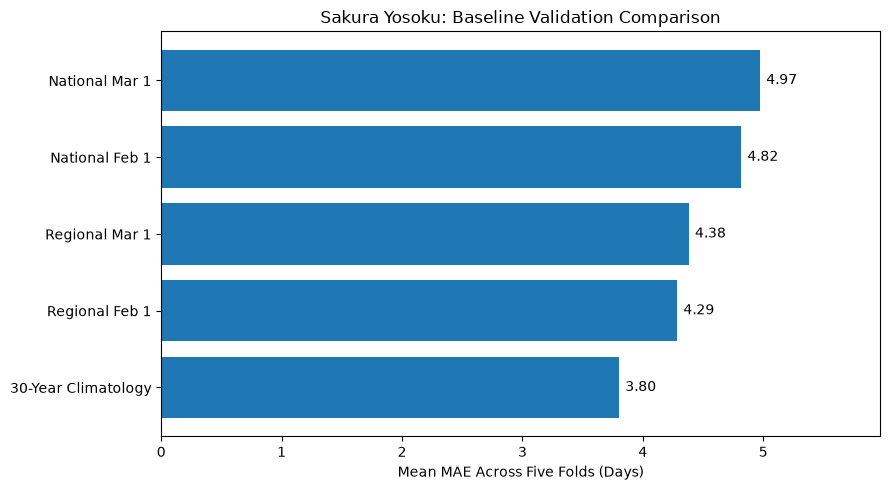

In [5]:

mae = comparison["MAE"].sort_values()

plt.figure(figsize=(9, 5))

bars = plt.barh(mae.index, mae.values)

for bar, value in zip(bars, mae.values):
    plt.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center"
    )

plt.xlabel("Mean MAE Across Five Folds (Days)")
plt.title("Sakura Yosoku: Baseline Validation Comparison")

plt.xlim(0, mae.max() * 1.2)
plt.tight_layout()
plt.show()


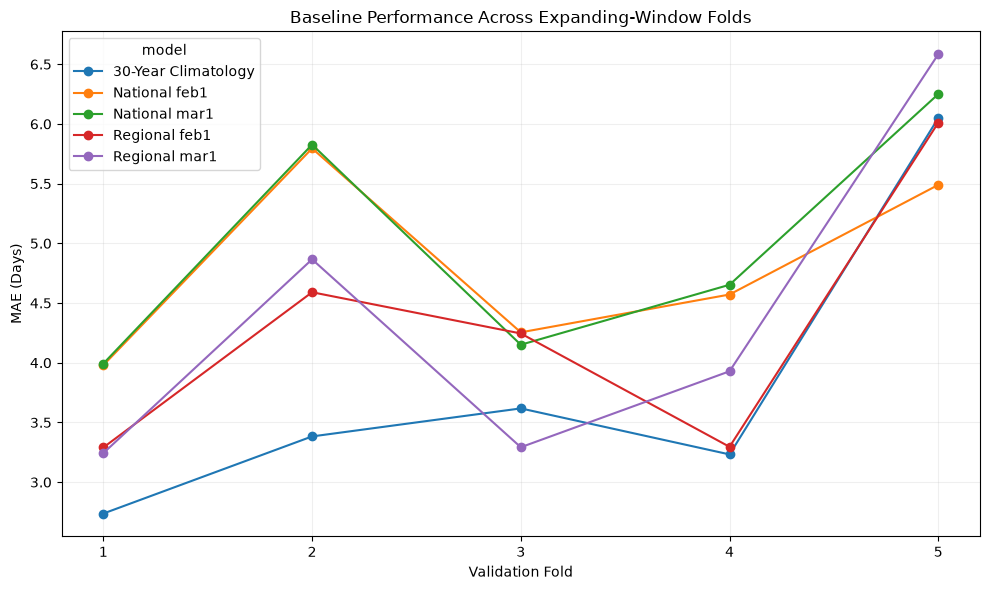

In [6]:

clim_plot = clim_folds[
    ["fold", "MAE"]
].copy()

clim_plot["fold"] = clim_plot["fold"].astype(int)

clim_plot["model"] = "30-Year Climatology"

national_plot = national_metrics[
    ["fold", "forecast_date", "MAE"]
].copy()

national_plot["model"] = (
    "National " + national_plot["forecast_date"]
)

regional_plot = regional_metrics[
    ["fold", "forecast_date", "MAE"]
].copy()

regional_plot["model"] = (
    "Regional " + regional_plot["forecast_date"]
)

plot_df = pd.concat([
    clim_plot[["fold", "MAE", "model"]],
    national_plot[["fold", "MAE", "model"]],
    regional_plot[["fold", "MAE", "model"]]
])

pivot = plot_df.pivot(
    index="fold",
    columns="model",
    values="MAE"
)

pivot.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.xlabel("Validation Fold")
plt.ylabel("MAE (Days)")
plt.title("Baseline Performance Across Expanding-Window Folds")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [7]:

comparison.to_csv(
    OUTPUT / "final_baseline_cv_comparison.csv"
)

print("Baseline benchmarking results saved!")


Baseline benchmarking results saved!


In [11]:
# ============================================================
# REGIONAL ERROR ANALYSIS
# ============================================================

# Use existing regional predictions
regional_analysis = regional.copy()

# Calculate absolute prediction error
regional_analysis["absolute_error"] = (
    regional_analysis["predicted_doy"]
    - regional_analysis["actual_doy"]
).abs()

# Calculate regional MAE
region_mae = (
    regional_analysis
    .groupby(["region", "forecast_date"])
    .agg(
        N=("absolute_error", "count"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

# Display results
display(region_mae.round(3))

,region,forecast_date,N,MAE
0,Chubu,feb1,110,3.591
1,Chubu,mar1,110,3.700
2,Chugoku,feb1,61,3.115
3,Chugoku,mar1,61,3.311
4,Hokkaido,feb1,35,5.114
5,Hokkaido,mar1,35,5.371
6,Kansai,feb1,89,3.371
7,Kansai,mar1,89,3.663
8,Kanto,feb1,81,5.383
9,Kanto,mar1,81,5.185


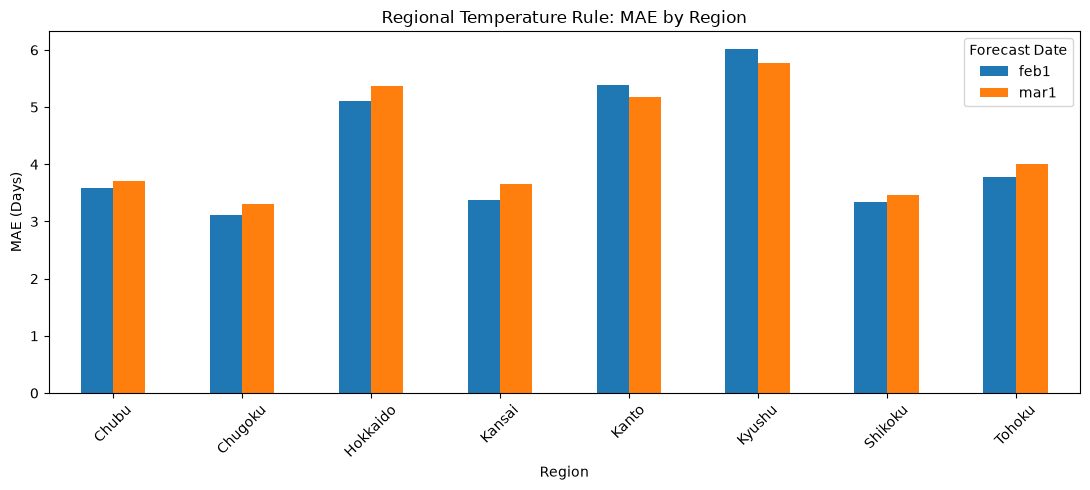

In [12]:
region_pivot = region_mae.pivot(
    index="region",
    columns="forecast_date",
    values="MAE"
)

ax = region_pivot.plot(
    kind="bar",
    figsize=(11, 5),
    rot=45
)

ax.set_title("Regional Temperature Rule: MAE by Region")
ax.set_xlabel("Region")
ax.set_ylabel("MAE (Days)")
ax.legend(title="Forecast Date")

plt.tight_layout()
plt.show()

In [13]:
# Compare national and regional temperature-rule errors
keys = ["fold", "forecast_date", "station_id", "year"]

national_compare = national[keys + [
    "actual_doy", "predicted_doy"
]].copy()

regional_compare = regional[keys + [
    "region", "actual_doy", "predicted_doy"
]].copy()

# Standardize station IDs
national_compare["station_id"] = (
    national_compare["station_id"].astype(str)
)

regional_compare["station_id"] = (
    regional_compare["station_id"].astype(str)
)

paired = regional_compare.merge(
    national_compare,
    on=keys,
    suffixes=("_regional", "_national"),
    validate="one_to_one"
)

assert (
    paired["actual_doy_regional"]
    == paired["actual_doy_national"]
).all(), "Target mismatch"

paired["AE_regional"] = (
    paired["predicted_doy_regional"]
    - paired["actual_doy_regional"]
).abs()

paired["AE_national"] = (
    paired["predicted_doy_national"]
    - paired["actual_doy_national"]
).abs()

regional_improvement = (
    paired.groupby(["region", "forecast_date"])
    .agg(
        N=("AE_regional", "count"),
        National_MAE=("AE_national", "mean"),
        Regional_MAE=("AE_regional", "mean")
    )
    .reset_index()
)

regional_improvement["MAE_reduction"] = (
    regional_improvement["National_MAE"]
    - regional_improvement["Regional_MAE"]
)

display(regional_improvement.round(3))

,region,forecast_date,N,National_MAE,Regional_MAE,MAE_reduction
0,Chubu,feb1,110,4.191,3.591,0.600
1,Chubu,mar1,110,3.991,3.700,0.291
2,Chugoku,feb1,61,3.148,3.115,0.033
3,Chugoku,mar1,61,3.361,3.311,0.049
4,Hokkaido,feb1,35,9.743,5.114,4.629
5,Hokkaido,mar1,35,9.229,5.371,3.857
6,Kansai,feb1,89,3.191,3.371,-0.180
7,Kansai,mar1,89,3.764,3.663,0.101
8,Kanto,feb1,81,4.716,5.383,-0.667
9,Kanto,mar1,81,4.852,5.185,-0.333


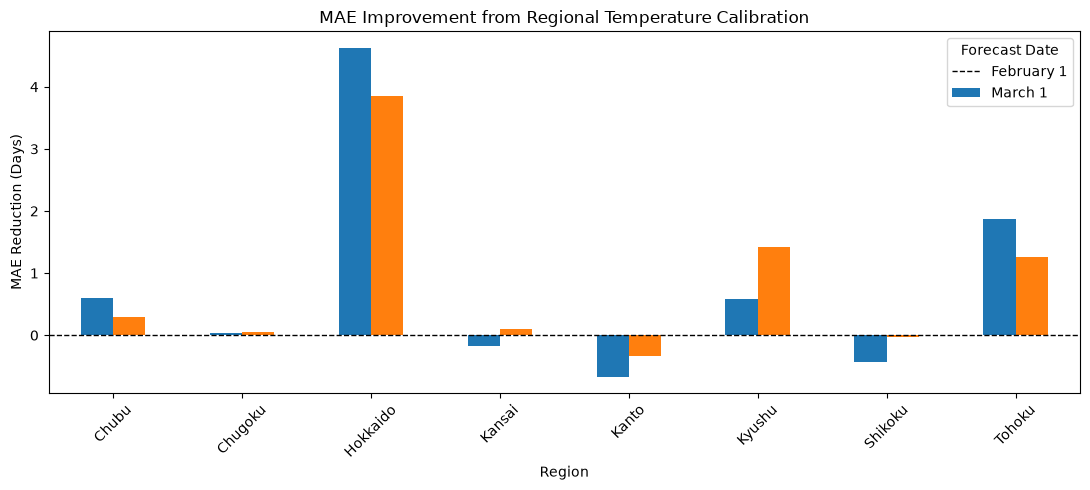

In [14]:

# Regional calibration improvement chart

improvement_plot = regional_improvement.pivot(
    index="region",
    columns="forecast_date",
    values="MAE_reduction"
)

ax = improvement_plot.plot(
    kind="bar",
    figsize=(11, 5),
    rot=45
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_title(
    "MAE Improvement from Regional Temperature Calibration"
)
ax.set_xlabel("Region")
ax.set_ylabel("MAE Reduction (Days)")
ax.legend(
    ["February 1", "March 1"],
    title="Forecast Date"
)

plt.tight_layout()
plt.show()


In [15]:

clim_predictions = pd.read_csv(
    OUTPUT / "climatology_30yr_cv_predictions.csv"
)

keys = ["fold", "station_id", "year"]

# Normalize identifiers
for df in [clim_predictions, national, regional]:
    df["station_id"] = df["station_id"].astype(str)

clim_keys = set(map(tuple, clim_predictions[keys].to_numpy()))

for name, data in [
    ("National Feb 1", national[national["forecast_date"] == "feb1"]),
    ("National Mar 1", national[national["forecast_date"] == "mar1"]),
    ("Regional Feb 1", regional[regional["forecast_date"] == "feb1"]),
    ("Regional Mar 1", regional[regional["forecast_date"] == "mar1"])
]:
    model_keys = set(map(tuple, data[keys].to_numpy()))

    print(
        name,
        "| Same sample:", clim_keys == model_keys,
        "| Observations:", len(data)
    )


National Feb 1 | Same sample: True | Observations: 575
National Mar 1 | Same sample: True | Observations: 575
Regional Feb 1 | Same sample: True | Observations: 575
Regional Mar 1 | Same sample: True | Observations: 575


In [16]:

from IPython.display import display, Markdown

summary = """
# Key Findings — Baseline Model Benchmarking

## 1. Overall Model Performance

Five-fold expanding-window cross-validation (2005–2014)
was used to evaluate the baseline models.

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| **30-Year Station Climatology** | **3.804** | **4.573** | **0.819** | 45.72% |
| National Temperature Rule — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional Temperature Rule — Feb 1 | 4.287 | 5.406 | 0.743 | **48.48%** |
| National Temperature Rule — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional Temperature Rule — Mar 1 | 4.383 | 5.532 | 0.726 | 48.23% |

*Results are unweighted averages across five validation folds,
not final test results.*

---

## 2. Key Findings

### Finding 1 — Station Climatology Achieved the Lowest Error

The 30-year Station Climatology achieved the lowest MAE
(3.804 days), RMSE (4.573 days), and highest R² (0.819).

This establishes historical station-level bloom timing
as a strong benchmark for the advanced regression models.

### Finding 2 — Regional Temperature Calibration Improved Accuracy

Compared with the national temperature threshold,
regional calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

This suggests that geographic differences in temperature
accumulation are important for full-bloom prediction.

### Finding 3 — Regional Improvements Were Uneven

The largest improvements occurred in:

- **Hokkaido:** 4.629-day MAE reduction (Feb 1)
- **Tohoku:** 1.867-day MAE reduction (Feb 1)

However, regional calibration increased prediction errors
in Kanto and Shikoku for both forecast dates.

Therefore, regional thresholds are not universally superior.

### Finding 4 — March 1 Did Not Consistently Outperform February 1

Despite incorporating observed February temperatures,
the regional March 1 model achieved a higher MAE
(4.383 days) than February 1 (4.287 days).

Additional weather information did not automatically
improve accuracy under the current forecasting assumptions.

### Finding 5 — Model Preference Depends on the Metric

- **Lowest MAE:** 30-Year Station Climatology (3.804 days)
- **Highest ±3-day hit rate:** Regional February 1 (48.48%)

The best benchmark therefore depends on whether the
business prioritizes average prediction error or
the proportion of forecasts within three days.

---

## 3. Model Limitations

- Station Climatology cannot capture unusual current-season weather.
- Future temperatures are estimated using historical daily averages.
- Regional thresholds cannot fully represent local microclimates.
- Regional calibration does not improve accuracy in every region.
- Leap-year handling and forecast-cutoff-safe weather imputation
  require final verification.
- Model configurations were compared using validation data;
  independent test performance has not yet been assessed.

---

## 4. Conclusion

**The 30-year Station Climatology is retained as the primary
historical benchmark because it achieved the lowest validation MAE.**

**The regionally calibrated temperature rule is retained as
the preferred temperature-based benchmark.**

Although regional calibration improved the national
temperature-rule approach, the 30-year climatology
remained more accurate on average.

These results establish the benchmarks for evaluating
the team's advanced regression models.

**The 2015–2025 test period remains untouched until
the team's final champion-model evaluation.**
"""

display(Markdown(summary))



# Key Findings — Baseline Model Benchmarking

## 1. Overall Model Performance

Five-fold expanding-window cross-validation (2005–2014)
was used to evaluate the baseline models.

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| **30-Year Station Climatology** | **3.804** | **4.573** | **0.819** | 45.72% |
| National Temperature Rule — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional Temperature Rule — Feb 1 | 4.287 | 5.406 | 0.743 | **48.48%** |
| National Temperature Rule — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional Temperature Rule — Mar 1 | 4.383 | 5.532 | 0.726 | 48.23% |

*Results are unweighted averages across five validation folds,
not final test results.*

---

## 2. Key Findings

### Finding 1 — Station Climatology Achieved the Lowest Error

The 30-year Station Climatology achieved the lowest MAE
(3.804 days), RMSE (4.573 days), and highest R² (0.819).

This establishes historical station-level bloom timing
as a strong benchmark for the advanced regression models.

### Finding 2 — Regional Temperature Calibration Improved Accuracy

Compared with the national temperature threshold,
regional calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

This suggests that geographic differences in temperature
accumulation are important for full-bloom prediction.

### Finding 3 — Regional Improvements Were Uneven

The largest improvements occurred in:

- **Hokkaido:** 4.629-day MAE reduction (Feb 1)
- **Tohoku:** 1.867-day MAE reduction (Feb 1)

However, regional calibration increased prediction errors
in Kanto and Shikoku for both forecast dates.

Therefore, regional thresholds are not universally superior.

### Finding 4 — March 1 Did Not Consistently Outperform February 1

Despite incorporating observed February temperatures,
the regional March 1 model achieved a higher MAE
(4.383 days) than February 1 (4.287 days).

Additional weather information did not automatically
improve accuracy under the current forecasting assumptions.

### Finding 5 — Model Preference Depends on the Metric

- **Lowest MAE:** 30-Year Station Climatology (3.804 days)
- **Highest ±3-day hit rate:** Regional February 1 (48.48%)

The best benchmark therefore depends on whether the
business prioritizes average prediction error or
the proportion of forecasts within three days.

---

## 3. Model Limitations

- Station Climatology cannot capture unusual current-season weather.
- Future temperatures are estimated using historical daily averages.
- Regional thresholds cannot fully represent local microclimates.
- Regional calibration does not improve accuracy in every region.
- Leap-year handling and forecast-cutoff-safe weather imputation
  require final verification.
- Model configurations were compared using validation data;
  independent test performance has not yet been assessed.

---

## 4. Conclusion

**The 30-year Station Climatology is retained as the primary
historical benchmark because it achieved the lowest validation MAE.**

**The regionally calibrated temperature rule is retained as
the preferred temperature-based benchmark.**

Although regional calibration improved the national
temperature-rule approach, the 30-year climatology
remained more accurate on average.

These results establish the benchmarks for evaluating
the team's advanced regression models.

**The 2015–2025 test period remains untouched until
the team's final champion-model evaluation.**
